In [1]:
import pandas as pd
import nibabel as nib
import numpy as np
import yaml
import os
import sys
import argparse
import glob

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [2]:
data_folder = "./test_recon_folder_4/bulk_data"
targets = np.load(os.path.join(data_folder,'targets_data.npy'))
preds = np.load(os.path.join(data_folder, "predicted_data.npy"))

n_subjects = targets.shape[0]
print(targets.shape)

(182, 1, 320, 153)


In [3]:
targets = targets.reshape(n_subjects, -1)
preds = preds.reshape(n_subjects, -1)

In [ ]:
ex = stats.pearsonr(preds, targets, axis=1).statistic

a = preds[0][0:10]
b = targets[0][0:10]
print(a)
print(b)

stats.pearsonr(a, b).statistic

[ 0.01745415  0.00199118  0.00981116  0.01096271  0.00190192  0.01229236
  0.00025112  0.02015558 -0.00195294  0.01219141]
[-0.4888602  -0.92971414 -0.15523557  0.02954005 -0.7762327   0.22176297
 -0.37387478 -0.2791065  -0.4781688  -0.83148664]
-0.00024348775


np.float32(0.36347324)

In [12]:
p1 = preds[0]
t1 = targets[0]

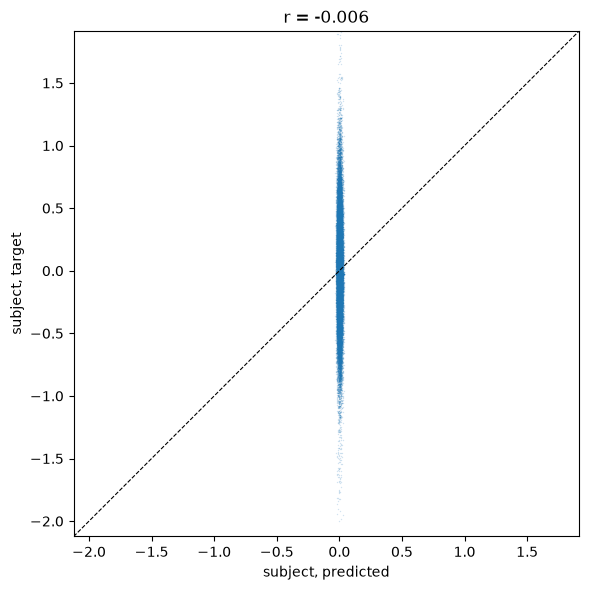

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(p1, t1, s=1, alpha=0.2, linewidths=0, rasterized=True)

lims = [min(p1.min(), t1.min()), max(p1.max(), t1.max())]
ax.plot(lims, lims, "k--", lw=0.8)   # y = x reference line
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_aspect("equal")

ax.set_xlabel("subject, predicted")
ax.set_ylabel("subject, target")
ax.set_title(f"r = {np.corrcoef(p1, t1)[0, 1]:.3f}")
plt.tight_layout()
plt.savefig("scatter.png", dpi=200)
plt.show()

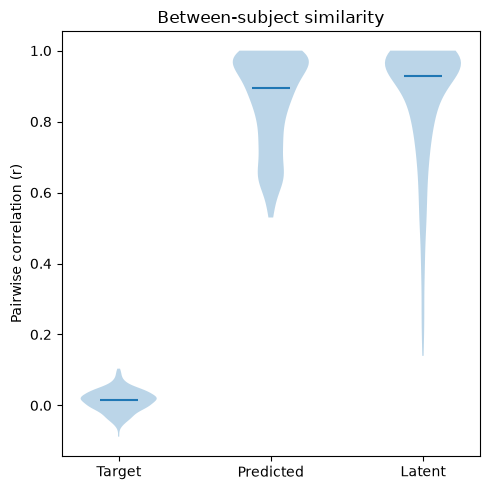

In [32]:
B = targs_R.shape[0]
iu = np.triu_indices(B, k=1)

target_r = targs_R[iu]
pred_r = preds_R[iu]
enc_r = e_R[iu]

# drop NaNs from constant rows, if any
target_r = target_r[~np.isnan(target_r)]
pred_r = pred_r[~np.isnan(pred_r)]
enc_r = enc_r[~np.isnan(enc_r)]

fig, ax = plt.subplots(figsize=(5, 5))
parts = ax.violinplot([target_r, pred_r, enc_r], positions=[1, 2, 3],
                      showmedians=True, showextrema=False)

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(['Target', 'Predicted', 'Latent'])
ax.set_ylabel('Pairwise correlation (r)')
ax.set_title('Between-subject similarity')
plt.tight_layout()
plt.show()

In [ ]:
np.save("pred_corr_low.npy", preds[338])
np.save("pred_corr_high.npy")

ValueError: m has more than 2 dimensions